# Patterned_surface 512×512 PnP-Flow inpainting

Loads the Patterned_surface model and a 512×512 normalized NPY or preprocessed PNG, applies a configurable square mask, runs PnP-Flow inpainting, and saves full-patch and zoomed comparison figures plus masked-region metrics.

Set `TEST_IMAGE_PATH` to an existing `.npy` or 512×512 `.png`, or use `None` and `TEST_SAMPLE_INDEX` to choose a held-out test NPY. A PNG from `clean/centercrop/resized/images` is normalized with its paired center crop, exactly as during training. The inpainting loop hard-clamps observed pixels after each step; with noiseless observations its data gradient is zero, so `NOISE_STD`, `LR_PNP`, and `ALPHA` do not change this default reconstruction.

Saved outputs may reflect an earlier input; rerun all cells after changing `TEST_IMAGE_PATH`.

In [ ]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Rectangle
from PIL import Image

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    candidate = repo_root.parent
    if (candidate / 'pnpflow').is_dir():
        repo_root = candidate
    else:
        raise RuntimeError('Open from the PnP-Flow repository or its notebooks directory.')
os.chdir(repo_root)

DATASET_NAME = 'sem_nffa_all10_centerresize_512'
CLASS_NAME = 'Patterned_surface'
# CLASS_NAME = 'Tips'
# CHECKPOINT_NAME = 'training_state_latest.pt'  # change to model_final.pt after training completes

RUN_NAME = '20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep'
# CHECKPOINT_NAME ='model_50.pt' 
CHECKPOINT_NAME = "model_final.pt"


# RUN_NAME ='20260923_140640_sem_nffa_all10_centerresize_512_ot_fp32_warmstart_model20_gb8_29ep'
# # CHECKPOINT_NAME = "model_70.pt"
# CHECKPOINT_NAME = "model_final.pt"
TEST_SAMPLE_INDEX = 0
# TEST_IMAGE_PATH = '/data2/marci/bselvaku/nffa_sem/clean/centercrop/resized/processed/train/Patterned_surface/L1_42f41ce892887c173c662419ff7e3885.npy'
# TEST_IMAGE_PATH = '/home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/data/sem_nffa_all10_centerresize_512/train/Patterned_surface/L1_42f41ce892887c173c662419ff7e3885.npy'
# TEST_IMAGE_PATH = '/data2/marci/bselvaku/nffa_sem/clean/centercrop/resized/processed/train/Patterned_surface/L1_0a0c79700d1436fb62403554680af5df.png'
# TEST_IMAGE_PATH ='/data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_fd2bb441a2cefdb5f02f85ad42cc5659.npy'
TEST_IMAGE_PATH = '/data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_e3c8008b5f85d5ce33243149f5aa8f2a.npy'
# TEST_IMAGE_PATH = '/data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_5d763f0aade2ad8ca626a0e9f437263f.npy'

#  Equivalent 512×512 PNG: /data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/images/Patterned_surface/L1_42f41ce892887c173c662419ff7e3885.png
# Your L1_0a0c79700d1436fb62403554680af5df image is under processed/train, not processed/val.
# Its 512×512 PNG is at /data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/images/Patterned_surface/L1_0a0c79700d1436fb62403554680af5df.png
# This particular image is in the TRAIN split; use TEST_IMAGE_PATH = None for held-out evaluation.
PNG_REFERENCE_CROP_PATH = None  # optional: supply the paired center-crop PNG for an arbitrary 512×512 PNG
BOX_SIZE = 64
BOX_TOP = 200
BOX_LEFT = 200
STEPS_PNP = int(os.environ.get('ROTATION_COMPARE_STEPS', '100'))
NUM_SAMPLES = int(os.environ.get('ROTATION_COMPARE_SAMPLES', '5'))
NOISE_STD = 0.01
LR_PNP = 1.0
ALPHA = 1.0
SEED = 0

checkpoint_path = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / CHECKPOINT_NAME
processed_root = repo_root / 'data' / DATASET_NAME
test_root = processed_root / 'test' / CLASS_NAME
if not checkpoint_path.is_file():
    raise FileNotFoundError(f'Checkpoint not found: {checkpoint_path}')
test_files = sorted(test_root.glob('*.npy'))
if not test_files:
    raise FileNotFoundError(f'No {CLASS_NAME} test patches under {test_root}')
if TEST_IMAGE_PATH is None:
    if not 0 <= TEST_SAMPLE_INDEX < len(test_files):
        raise IndexError(f'TEST_SAMPLE_INDEX={TEST_SAMPLE_INDEX}; found {len(test_files)} test patches.')
    patch_path = test_files[TEST_SAMPLE_INDEX]
else:
    patch_path = Path(TEST_IMAGE_PATH).expanduser()
    if not patch_path.is_absolute():
        patch_path = repo_root / patch_path
    patch_path = patch_path.resolve()
    if not patch_path.is_file():
        matches = [processed_root / split / CLASS_NAME / patch_path.name
                   for split in ('train', 'val', 'test')
                   if (processed_root / split / CLASS_NAME / patch_path.name).is_file()]
        hint = f' The file exists under {matches[0]}' if matches else ''
        raise FileNotFoundError(f'Input image not found: {patch_path}.{hint}')
    if patch_path.suffix.lower() not in {'.npy', '.png'}:
        raise ValueError(f'Expected a processed .npy or .png image, got {patch_path}')

split_matches = [split for split in ('train', 'val', 'test')
                 if (processed_root / split / CLASS_NAME / f'{patch_path.stem}.npy').is_file()]
input_split = split_matches[0] if len(split_matches) == 1 else 'unknown'

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)

print(f'Checkpoint: {checkpoint_path}')
print(f'{CLASS_NAME} held-out test patches available: {len(test_files)}')
print(f'Selected input: {patch_path}; split: {input_split}')
if input_split == 'train':
    print('Warning: this is a training image; its masked PSNR is not a held-out evaluation.')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(device)}')

Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10_centerresize_512/ot/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/model_final.pt
Patterned_surface held-out test patches available: 476
Selected input: /data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_5d763f0aade2ad8ca626a0e9f437263f.npy; split: test
Device: cuda:0
GPU: Tesla V100-SXM2-32GB


In [16]:
from pnpflow.utils import define_model

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = 512

model, _ = define_model(ModelArgs())
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
state_dict = checkpoint.get('model_state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
model.load_state_dict(state_dict, strict=True)
model.to(device).eval()
if any(not torch.isfinite(p).all().item() for p in model.parameters()):
    raise ValueError(f'Checkpoint contains non-finite parameters: {checkpoint_path}')

image_format = patch_path.suffix.lower().lstrip('.')
normalization_reference = 'stored normalized NPY'
normalization_low_high = None
clean_root = processed_root.resolve().parents[2]
if image_format == 'npy':
    patch = np.load(patch_path, allow_pickle=False).astype(np.float32)
    if patch.ndim == 3 and patch.shape[0] == 1:
        patch = patch[0]
    if not np.isfinite(patch).all() or patch.min() < -1.001 or patch.max() > 1.001:
        raise ValueError(f'Expected a normalized finite NPY in [-1, 1], got {patch_path}')
else:
    with Image.open(patch_path) as handle:
        if handle.size != (512, 512):
            preview = clean_root / 'centercrop_resized' / 'resized' / 'images' / CLASS_NAME / patch_path.name
            hint = f' Use the 512x512 preview at {preview}' if preview.is_file() else ''
            raise ValueError(f'Expected a 512x512 PNG, got {handle.size} from {patch_path}.{hint}')
        pixels = np.asarray(handle.convert('L'), dtype=np.uint8)
    preview_root = clean_root / 'centercrop_resized' / 'resized' / 'images'
    if PNG_REFERENCE_CROP_PATH is not None:
        reference_path = Path(PNG_REFERENCE_CROP_PATH).expanduser()
        if not reference_path.is_absolute():
            reference_path = repo_root / reference_path
        reference_path = reference_path.resolve()
        if not reference_path.is_file():
            raise FileNotFoundError(f'PNG normalization reference not found: {reference_path}')
    else:
        try:
            relative = patch_path.resolve().relative_to(preview_root.resolve())
            reference_path = clean_root / 'centercrop' / relative
        except ValueError:
            reference_path = None
    if reference_path is not None and reference_path.is_file():
        with Image.open(reference_path) as handle:
            reference = np.asarray(handle.convert('L'), dtype=np.uint8)
        normalization_reference = str(reference_path)
    else:
        reference = pixels
        normalization_reference = 'input PNG percentiles (no paired center crop found)'
        print('Warning: no paired center crop found; PNG normalization may differ from training.')
    low, high = np.percentile(reference.astype(np.float32), (1, 99))
    if not high > low:
        raise ValueError(f'PNG normalization has no usable intensity range: [{low}, {high}]')
    patch = (2.0 * np.clip((pixels.astype(np.float32) - low) / (high - low), 0, 1) - 1.0)
    patch = patch.astype(np.float16).astype(np.float32)  # match stored training NPY quantization
    normalization_low_high = [float(low), float(high)]

if patch.shape != (512, 512) or not np.isfinite(patch).all():
    raise ValueError(f'Expected a finite 512 x 512 image, got {patch.shape} from {patch_path}')
clean = torch.from_numpy(patch)[None, None].to(device=device)
print(f'Loaded {image_format.upper()} input with shape {tuple(clean.shape)}')
print(f'Normalization source: {normalization_reference}')
print(f'Normalized range: {clean.min().item():.3f} to {clean.max().item():.3f}')

Loaded NPY input with shape (1, 1, 512, 512)
Normalization source: stored normalized NPY
Normalized range: -1.000 to 1.000


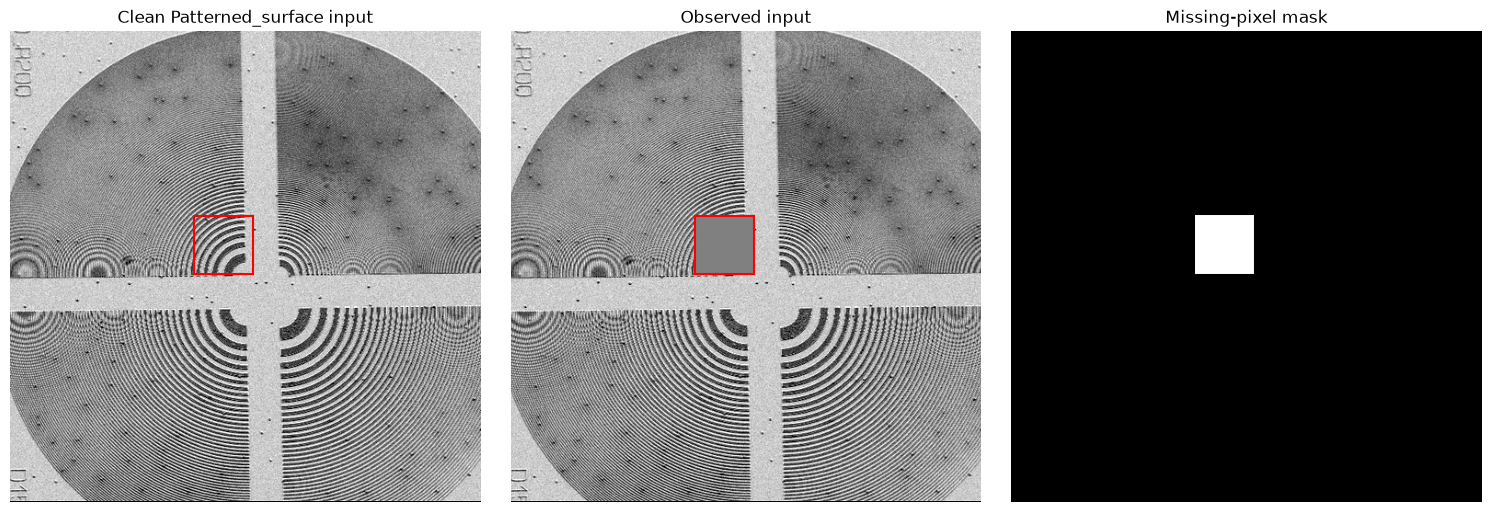

Mask box: y=200:264, x=200:264
Missing area: 1.56% of the patch


In [17]:
height, width = clean.shape[-2:]
if not 0 < BOX_SIZE < min(height, width):
    raise ValueError(f'BOX_SIZE must be between 1 and {min(height, width) - 1}.')
if not (0 <= BOX_TOP <= height - BOX_SIZE and 0 <= BOX_LEFT <= width - BOX_SIZE):
    raise ValueError('The box coordinates fall outside the test patch.')
if STEPS_PNP < 1 or NUM_SAMPLES < 1 or NOISE_STD <= 0:
    raise ValueError('STEPS_PNP, NUM_SAMPLES, and NOISE_STD must be positive.')

known_mask = torch.ones_like(clean)
known_mask[:, :, BOX_TOP:BOX_TOP + BOX_SIZE, BOX_LEFT:BOX_LEFT + BOX_SIZE] = 0
missing_mask = known_mask == 0
observed = known_mask * clean
clean_np = clean[0, 0].cpu().numpy()
observed_np = observed[0, 0].cpu().numpy()
missing_np = missing_mask[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes[0].imshow(clean_np, cmap='gray', vmin=-1, vmax=1)
axes[0].set_title('Clean Patterned_surface input')
axes[1].imshow(observed_np, cmap='gray', vmin=-1, vmax=1)
axes[1].set_title('Observed input')
axes[2].imshow(missing_np, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Missing-pixel mask')
for ax in axes:
    ax.axis('off')
for ax in axes[:2]:
    ax.add_patch(Rectangle((BOX_LEFT, BOX_TOP), BOX_SIZE, BOX_SIZE, fill=False, edgecolor='red', linewidth=1.5))
plt.show()
print(f'Mask box: y={BOX_TOP}:{BOX_TOP + BOX_SIZE}, x={BOX_LEFT}:{BOX_LEFT + BOX_SIZE}')
print(f'Missing area: {100 * missing_mask.float().mean().item():.2f}% of the patch')

In [18]:
@torch.inference_mode()
def pnp_flow_box_inpaint(model, clean, known_mask):
    missing = 1.0 - known_mask
    observed = known_mask * clean
    x = observed.clone()
    lr = NOISE_STD ** 2 * LR_PNP
    delta = 1.0 / STEPS_PNP
    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), delta * iteration, device=x.device, dtype=x.dtype)
        t_view = t.view(-1, 1, 1, 1)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(-1, 1, 1, 1)
        data_gradient = known_mask * (known_mask * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient
        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            z_tilde = t_view * z + (1.0 - t_view) * torch.randn_like(z)
            velocity = model(z_tilde, t)
            x_new += z_tilde + (1.0 - t_view) * velocity
        x_new /= NUM_SAMPLES
        x = known_mask * observed + missing * x_new
        if (iteration + 1) % 10 == 0 or iteration == 0:
            print(f'PnP iteration {iteration + 1}/{STEPS_PNP}')
    return x.clamp(-1.0, 1.0)

torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
start_time = time.perf_counter()
reconstruction = pnp_flow_box_inpaint(model, clean, known_mask)
if device.type == 'cuda':
    torch.cuda.synchronize(device)
elapsed_seconds = time.perf_counter() - start_time
reconstruction_np = reconstruction[0, 0].cpu().numpy()
error = reconstruction_np - clean_np
masked_mse = float(np.mean(error[missing_np] ** 2))
zero_fill_mse = float(np.mean(clean_np[missing_np] ** 2))
known_change = float(np.max(np.abs(reconstruction_np[~missing_np] - observed_np[~missing_np])))
masked_psnr = float(10.0 * np.log10(4.0 / max(masked_mse, 1e-12)))
zero_fill_psnr = float(10.0 * np.log10(4.0 / max(zero_fill_mse, 1e-12)))
print(f'Masked-region PSNR: {masked_psnr:.2f} dB (zero-fill baseline: {zero_fill_psnr:.2f} dB)')
print(f'Maximum known-pixel change: {known_change:.3g}')
print(f'Inference time: {elapsed_seconds:.1f} seconds')

PnP iteration 1/100


PnP iteration 10/100
PnP iteration 20/100
PnP iteration 30/100
PnP iteration 40/100
PnP iteration 50/100
PnP iteration 60/100
PnP iteration 70/100
PnP iteration 80/100
PnP iteration 90/100
PnP iteration 100/100
Masked-region PSNR: 11.88 dB (zero-fill baseline: 11.54 dB)
Maximum known-pixel change: 0
Inference time: 97.1 seconds


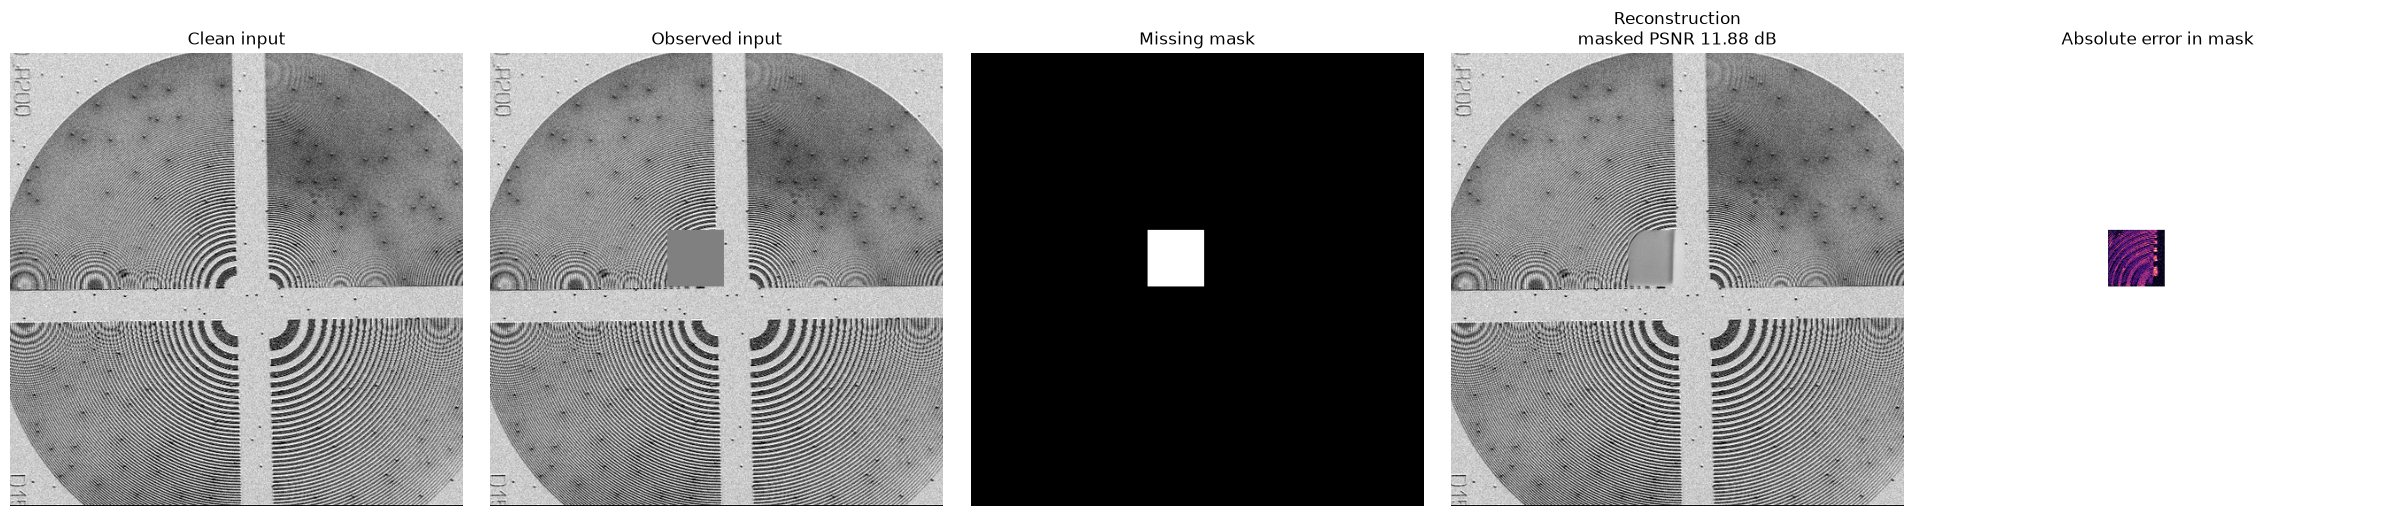

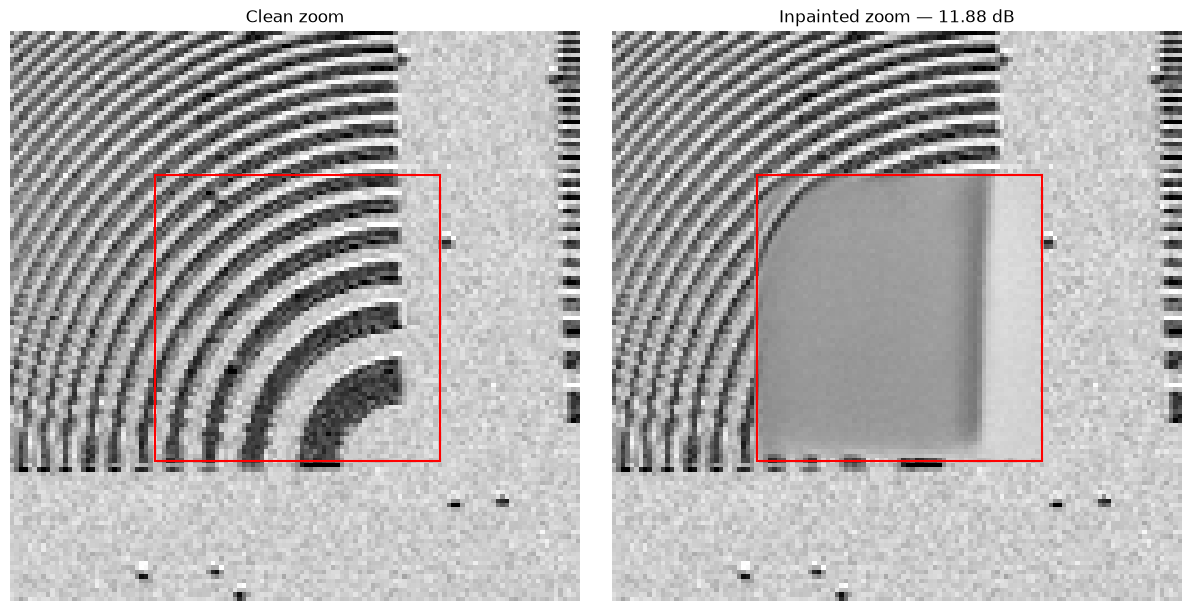

Saved full figure: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep_Patterned_surface_rotation_comparison/box_test_L1_5d763f0aade2ad8ca626a0e9f437263f_mask64.png
Saved zoom figure: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep_Patterned_surface_rotation_comparison/box_test_L1_5d763f0aade2ad8ca626a0e9f437263f_mask64_zoom.png
Saved metrics: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/notebooks/outputs/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep_Patterned_surface_rotation_comparison/box_test_L1_5d763f0aade2ad8ca626a0e9f437263f_mask64_metrics.json


In [19]:
error_display = np.where(missing_np, np.abs(error), np.nan)
fig, axes = plt.subplots(1, 5, figsize=(24, 5), constrained_layout=True)
panels = [(clean_np, 'Clean input', 'gray'), (observed_np, 'Observed input', 'gray'),
          (missing_np, 'Missing mask', 'gray'),
          (reconstruction_np, f'Reconstruction\nmasked PSNR {masked_psnr:.2f} dB', 'gray'),
          (error_display, 'Absolute error in mask', 'magma')]
for ax, (image, title, cmap) in zip(axes, panels):
    if cmap == 'magma':
        ax.imshow(image, cmap=cmap, vmin=0, vmax=max(float(np.nanmax(image)), 1e-6))
    elif title == 'Missing mask':
        ax.imshow(image, cmap=cmap, vmin=0, vmax=1)
    else:
        ax.imshow(image, cmap=cmap, vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis('off')
plt.show()

pad = 32
y0, y1 = max(0, BOX_TOP - pad), min(height, BOX_TOP + BOX_SIZE + pad)
x0, x1 = max(0, BOX_LEFT - pad), min(width, BOX_LEFT + BOX_SIZE + pad)
zoom_fig, zoom_axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
zoom_axes[0].imshow(clean_np[y0:y1, x0:x1], cmap='gray', vmin=-1, vmax=1)
zoom_axes[0].set_title('Clean zoom')
zoom_axes[1].imshow(reconstruction_np[y0:y1, x0:x1], cmap='gray', vmin=-1, vmax=1)
zoom_axes[1].set_title(f'Inpainted zoom — {masked_psnr:.2f} dB')
for ax in zoom_axes:
    ax.add_patch(Rectangle((BOX_LEFT - x0, BOX_TOP - y0), BOX_SIZE, BOX_SIZE, fill=False, edgecolor='red', linewidth=1.5))
    ax.axis('off')
plt.show()

output_dir = repo_root / 'notebooks' / 'outputs' / f'{RUN_NAME}_{CLASS_NAME}_rotation_comparison'
output_dir.mkdir(parents=True, exist_ok=True)
output_stem = f'box_{input_split}_{patch_path.stem}_mask{BOX_SIZE}'
figure_path = output_dir / f'{output_stem}.png'
zoom_path = output_dir / f'{output_stem}_zoom.png'
reconstruction_path = output_dir / f'{output_stem}_reconstruction.npy'
metrics_path = output_dir / f'{output_stem}_metrics.json'
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
zoom_fig.savefig(zoom_path, dpi=160, bbox_inches='tight')
np.save(reconstruction_path, reconstruction_np.astype(np.float32))
metrics = {'class_name': CLASS_NAME, 'checkpoint': str(checkpoint_path),
           'input_image': str(patch_path), 'input_split': input_split,
           'input_format': image_format, 'normalization_reference': normalization_reference,
           'normalization_low_high': normalization_low_high,
           'box': {'top': BOX_TOP, 'left': BOX_LEFT, 'size': BOX_SIZE},
           'steps': STEPS_PNP, 'num_samples': NUM_SAMPLES, 'noise_std': NOISE_STD,
           'masked_psnr_db': masked_psnr,
           'zero_fill_baseline_masked_psnr_db': zero_fill_psnr,
           'max_known_pixel_change': known_change, 'inference_seconds': elapsed_seconds}
metrics_path.write_text(json.dumps(metrics, indent=2) + '\n')
print(f'Saved full figure: {figure_path}')
print(f'Saved zoom figure: {zoom_path}')
print(f'Saved metrics: {metrics_path}')

## Rotation comparison
Rotate the image and its missing box together by 90 degrees counterclockwise. Both rows evaluate the same underlying pixels. Set ROTATION_K to 1, 2, or 3 for 90, 180, or 270 degrees. PSNR uses data range 2 for normalized images in [-1, 1]. The two reconstructions use seeded stochastic draws; their noise is not rotated together.


PnP iteration 1/100


PnP iteration 10/100
PnP iteration 20/100
PnP iteration 30/100
PnP iteration 40/100
PnP iteration 50/100
PnP iteration 60/100
PnP iteration 70/100
PnP iteration 80/100
PnP iteration 90/100
PnP iteration 100/100


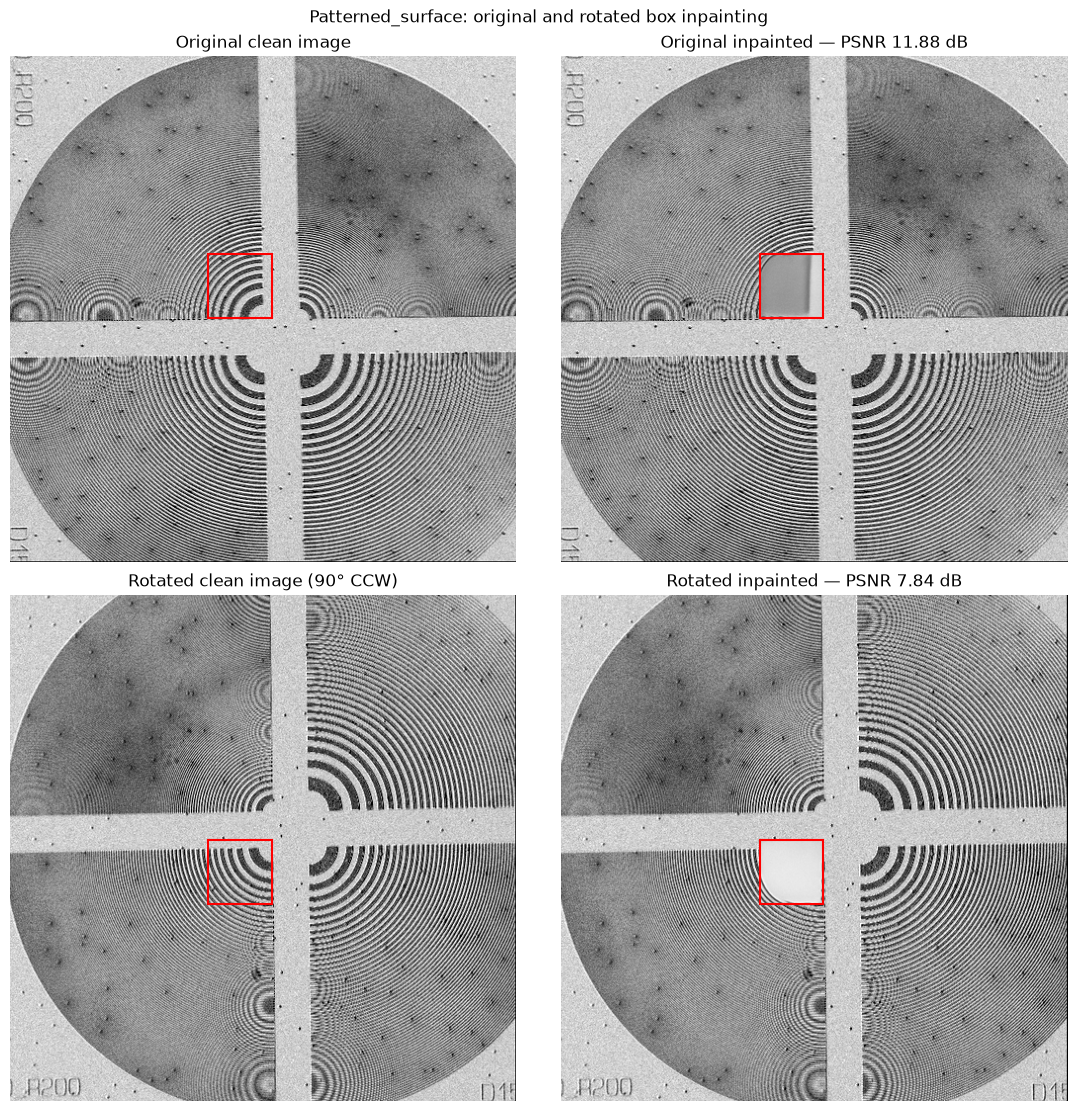

{
  "checkpoint": "/home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10_centerresize_512/ot/20260923_203800_sem_nffa_Patterned_surface_512_fp32_from_model20_gb8_130ep/model_final.pt",
  "input_image": "/data2/marci/bselvaku/nffa_sem/clean/centercrop_resized/resized/processed/test/Patterned_surface/L1_5d763f0aade2ad8ca626a0e9f437263f.npy",
  "input_split": "test",
  "rotation_degrees_ccw": 90,
  "mask_rotated_with_image": true,
  "box": {
    "top": 200,
    "left": 200,
    "size": 64
  },
  "steps_pnp": 100,
  "num_samples": 5,
  "seed": 0,
  "original_masked": {
    "mse": 0.25915685296058655,
    "mae": 0.42145854234695435,
    "psnr_db": 11.884972938243523,
    "max_observed_pixel_change": 0.0
  },
  "rotated_masked": {
    "mse": 0.6570565700531006,
    "mae": 0.6348979473114014,
    "psnr_db": 7.844572290676273,
    "max_observed_pixel_change": 0.0
  },
  "rotation_back_reconstruction_mae_in_mask": 0.48038893938064575,
  "rotation_inference_s

In [20]:
ROTATION_K = 1  # counterclockwise quarter-turns
if ROTATION_K not in (1, 2, 3):
    raise ValueError('ROTATION_K must be 1, 2, or 3.')
rotated_clean = torch.rot90(clean, ROTATION_K, dims=(-2, -1))
rotated_known = torch.rot90(known_mask, ROTATION_K, dims=(-2, -1))
rotated_missing = rotated_known == 0
torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
rotation_start = time.perf_counter()
rotated_reconstruction = pnp_flow_box_inpaint(model, rotated_clean, rotated_known)
if device.type == 'cuda':
    torch.cuda.synchronize(device)
rotation_seconds = time.perf_counter() - rotation_start

rotated_clean_np = rotated_clean[0, 0].cpu().numpy()
rotated_reconstruction_np = rotated_reconstruction[0, 0].cpu().numpy()
rotated_missing_np = rotated_missing[0, 0].cpu().numpy()
rotated_back_np = torch.rot90(rotated_reconstruction, -ROTATION_K, dims=(-2, -1))[0, 0].cpu().numpy()

def masked_metrics(target, prediction, missing):
    difference = prediction - target
    mse = float(np.mean(difference[missing] ** 2))
    return {
        'mse': mse,
        'mae': float(np.mean(np.abs(difference[missing]))),
        'psnr_db': float(10 * np.log10(4.0 / max(mse, 1e-12))),
        'max_observed_pixel_change': float(np.max(np.abs(difference[~missing]))),
    }

original_metrics = masked_metrics(clean_np, reconstruction_np, missing_np)
rotated_metrics = masked_metrics(rotated_clean_np, rotated_reconstruction_np, rotated_missing_np)
rotation_difference = float(np.mean(np.abs(rotated_back_np[missing_np] - reconstruction_np[missing_np])))

comparison_fig, comparison_axes = plt.subplots(2, 2, figsize=(11, 11), constrained_layout=True)
panels = [
    (clean_np, 'Original clean image', missing_np),
    (reconstruction_np, f"Original inpainted — PSNR {original_metrics['psnr_db']:.2f} dB", missing_np),
    (rotated_clean_np, f'Rotated clean image ({90 * ROTATION_K}° CCW)', rotated_missing_np),
    (rotated_reconstruction_np, f"Rotated inpainted — PSNR {rotated_metrics['psnr_db']:.2f} dB", rotated_missing_np),
]
for ax, (image, title, mask) in zip(comparison_axes.flat, panels):
    ax.imshow(image, cmap='gray', vmin=-1, vmax=1)
    ys, xs = np.where(mask)
    ax.add_patch(Rectangle((xs.min(), ys.min()), xs.max() - xs.min() + 1, ys.max() - ys.min() + 1,
                           fill=False, edgecolor='red', linewidth=1.5))
    ax.set_title(title)
    ax.axis('off')
comparison_fig.suptitle(f'{CLASS_NAME}: original and rotated box inpainting')
comparison_path = output_dir / f'{output_stem}_rotation_{90 * ROTATION_K}_comparison.png'
comparison_fig.savefig(comparison_path, dpi=160, bbox_inches='tight')
plt.show()

comparison_metrics = {
    'checkpoint': str(checkpoint_path), 'input_image': str(patch_path), 'input_split': input_split,
    'rotation_degrees_ccw': 90 * ROTATION_K, 'mask_rotated_with_image': True,
    'box': {'top': BOX_TOP, 'left': BOX_LEFT, 'size': BOX_SIZE},
    'steps_pnp': STEPS_PNP, 'num_samples': NUM_SAMPLES, 'seed': SEED,
    'original_masked': original_metrics, 'rotated_masked': rotated_metrics,
    'rotation_back_reconstruction_mae_in_mask': rotation_difference,
    'rotation_inference_seconds': rotation_seconds,
}
comparison_metrics_path = output_dir / f'{output_stem}_rotation_{90 * ROTATION_K}_metrics.json'
comparison_metrics_path.write_text(json.dumps(comparison_metrics, indent=2) + '\n')
np.save(output_dir / f'{output_stem}_rotation_{90 * ROTATION_K}_reconstruction.npy',
        rotated_reconstruction_np.astype(np.float32))
print(json.dumps(comparison_metrics, indent=2))
print(f'Saved comparison: {comparison_path}')
print(f'Saved comparison metrics: {comparison_metrics_path}')
